<div>
<img src="img/matplotlib-logo.png" width="500"/>
</div>

# Introduction à Matplotlib — nouveaux exemples

Dans ce TP, nous allons utiliser **Matplotlib** pour représenter différents types de données.

Les objectifs sont :

1. tracer la courbe d'une fonction ;
2. représenter des données discrètes avec des barres d'erreur ;
3. organiser plusieurs graphiques dans une même figure ;
4. afficher un diagramme en barres ;
5. afficher un diagramme circulaire ;
6. afficher un diagramme à moustaches.



In [1]:
# Mise en place de l'environnement
%matplotlib inline

import matplotlib.pyplot as plt
import numpy as np

plt.style.use("seaborn-v0_8-whitegrid")

## 1. Tracer la courbe d'une fonction

Commençons par représenter une fonction de **décroissance exponentielle**.

La variable `fig` représente la figure complète, tandis que `ax` correspond à la zone dans laquelle
le graphique est tracé.

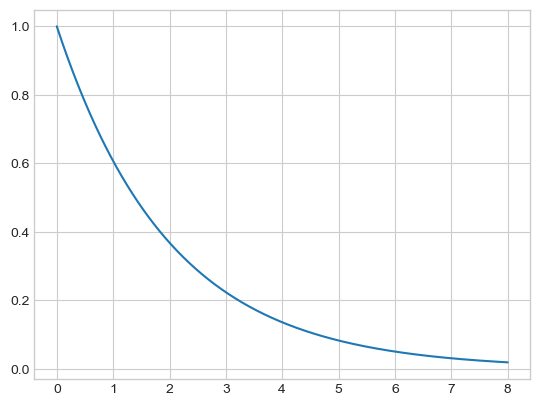

In [2]:
fig = plt.figure()
ax = plt.axes()

# 500 valeurs régulièrement espacées entre 0 et 8
x = np.linspace(0, 8, 500)

# Décroissance exponentielle
y = np.exp(-0.5 * x)

plt.plot(x, y)
plt.show()

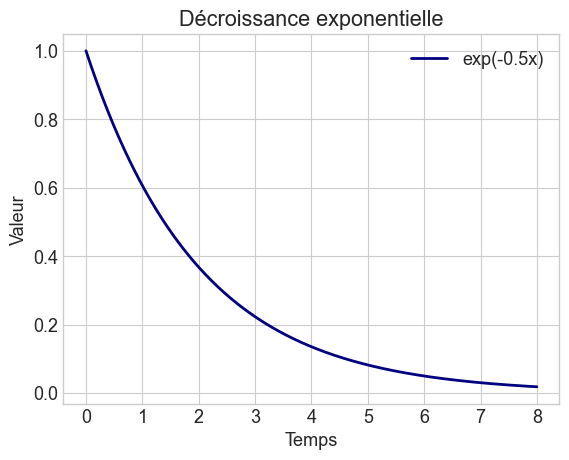

In [3]:
# Personnalisation de la courbe
plt.rcParams.update({"font.size": 13})

fig = plt.figure()
ax = plt.axes()

plt.plot(
    x,
    np.exp(-0.5 * x),
    color="navy",
    linestyle="-",
    linewidth=2,
    label="exp(-0.5x)"
)

plt.title("Décroissance exponentielle")
plt.xlabel("Temps")
plt.ylabel("Valeur")
plt.legend(loc="upper right")
plt.show()

<span style="color:blue">**QUESTION : Modifier le code précédent pour afficher la fonction `log(1+x)` avec une courbe pointillée et des marqueurs circulaires.**</span>

<span style="color:red">**CORRECTION :** On utilise `np.log1p(x)` pour calculer `log(1+x)`, `linestyle='--'` pour une ligne pointillée et `marker='o'` pour afficher des marqueurs.</span>

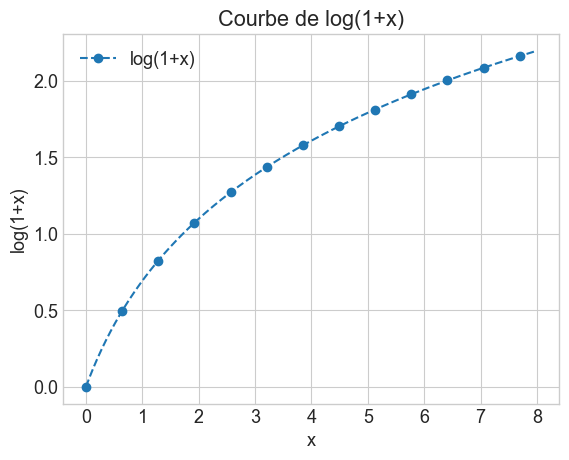

In [4]:
fig = plt.figure()
ax = plt.axes()

plt.plot(
    x,
    np.log1p(x),
    linestyle="--",
    marker="o",
    markevery=40,
    label="log(1+x)"
)

plt.title("Courbe de log(1+x)")
plt.xlabel("x")
plt.ylabel("log(1+x)")
plt.legend()
plt.show()

## 2. Visualiser des données discrètes

Dans la vie réelle, les mesures comportent souvent une part d'incertitude.

Imaginons que l'on relève la température d'une salle à différentes heures.
Chaque mesure possède une incertitude estimée à ±0,4 °C.

La fonction `errorbar` permet d'afficher simultanément les points mesurés et leurs barres d'erreur.

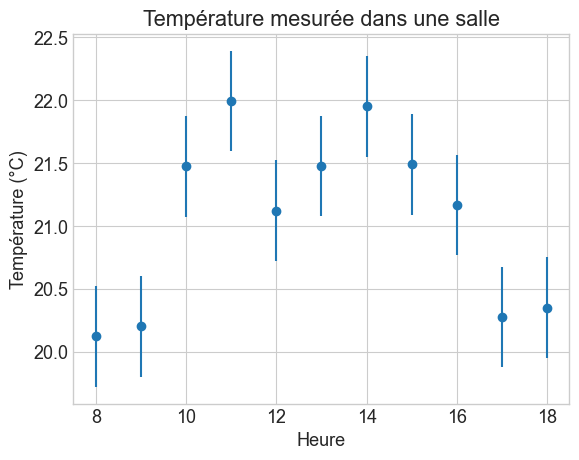

In [5]:
rng = np.random.default_rng(42)

heures = np.arange(8, 19)
temperature_theorique = 20 + 2 * np.sin((heures - 8) / 10 * np.pi)
incertitude = 0.4

temperature_mesuree = (
    temperature_theorique
    + rng.normal(0, incertitude, size=len(heures))
)

plt.errorbar(
    heures,
    temperature_mesuree,
    yerr=incertitude,
    fmt="o"
)

plt.xlabel("Heure")
plt.ylabel("Température (°C)")
plt.title("Température mesurée dans une salle")
plt.show()

<span style="color:blue">**QUESTION : Que signifient les principaux arguments `x`, `y`, `yerr` et `fmt` de `plt.errorbar` ?**</span>

<span style="color:red">**CORRECTION :** `x` contient les abscisses, `y` les valeurs mesurées, `yerr` la taille des incertitudes verticales et `fmt` contrôle l'apparence des points et éventuellement de la ligne.</span>

On peut personnaliser davantage l'affichage des mesures et de leurs incertitudes.

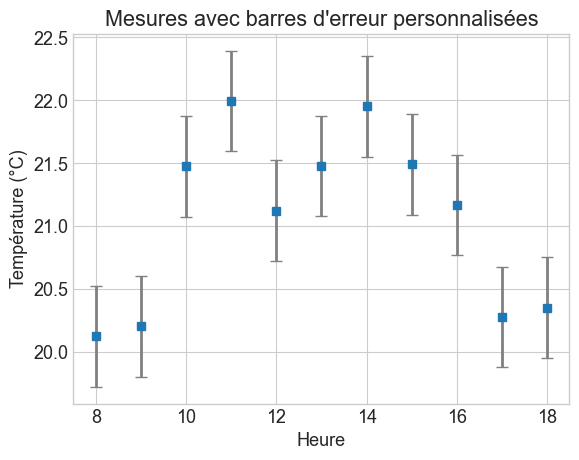

In [6]:
plt.errorbar(
    heures,
    temperature_mesuree,
    yerr=incertitude,
    fmt="s",
    ecolor="gray",
    elinewidth=2,
    capsize=4
)

plt.xlabel("Heure")
plt.ylabel("Température (°C)")
plt.title("Mesures avec barres d'erreur personnalisées")
plt.show()

<span style="color:blue">**QUESTION : Modifier le graphique pour représenter une incertitude de ±0,8 °C avec des marqueurs triangulaires.**</span>

<span style="color:red">**CORRECTION :** `yerr=0.8` fixe la nouvelle incertitude et `fmt='^'` utilise un marqueur triangulaire.</span>

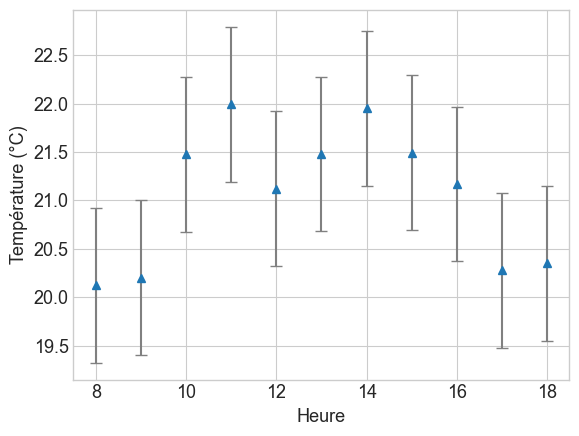

In [7]:
plt.errorbar(
    heures,
    temperature_mesuree,
    yerr=0.8,
    fmt="^",
    ecolor="gray",
    capsize=4
)

plt.xlabel("Heure")
plt.ylabel("Température (°C)")
plt.show()

## 3. Visualiser des données continues et organiser plusieurs graphiques

Pour une courbe continue, une incertitude peut être représentée sous la forme d'une **zone** autour de la courbe,
à l'aide de `fill_between`.

Nous allons représenter l'évolution moyenne du nombre de visiteurs d'un site au cours d'une journée.

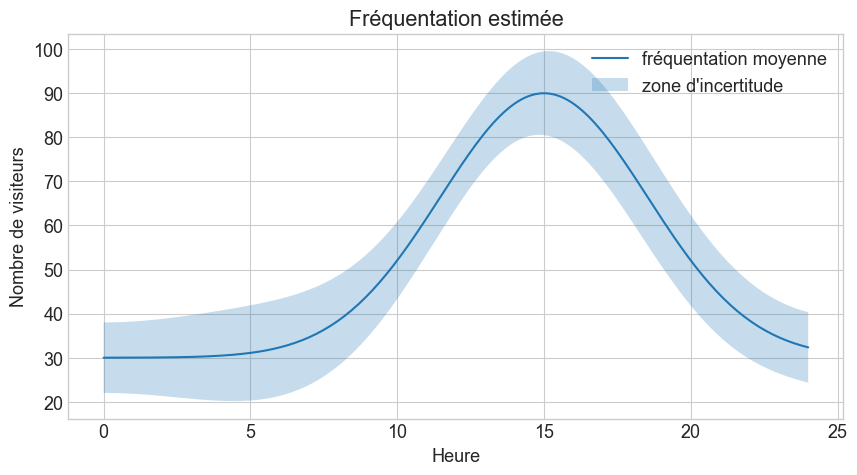

In [8]:
temps = np.linspace(0, 24, 200)
visiteurs = 30 + 60 * np.exp(-((temps - 15) / 5) ** 2)
marge = 8 + 3 * np.sin(temps / 24 * 2 * np.pi) ** 2

fig, ax = plt.subplots(figsize=(10, 5))

ax.plot(temps, visiteurs, label="fréquentation moyenne")
ax.fill_between(
    temps,
    visiteurs - marge,
    visiteurs + marge,
    alpha=0.25,
    label="zone d'incertitude"
)

ax.set(
    xlabel="Heure",
    ylabel="Nombre de visiteurs",
    title="Fréquentation estimée"
)
ax.legend()
plt.show()

Matplotlib permet également d'ajouter plusieurs sous-graphiques dans une même figure.
La méthode `add_subplot(n_lignes, n_colonnes, position)` précise la disposition.

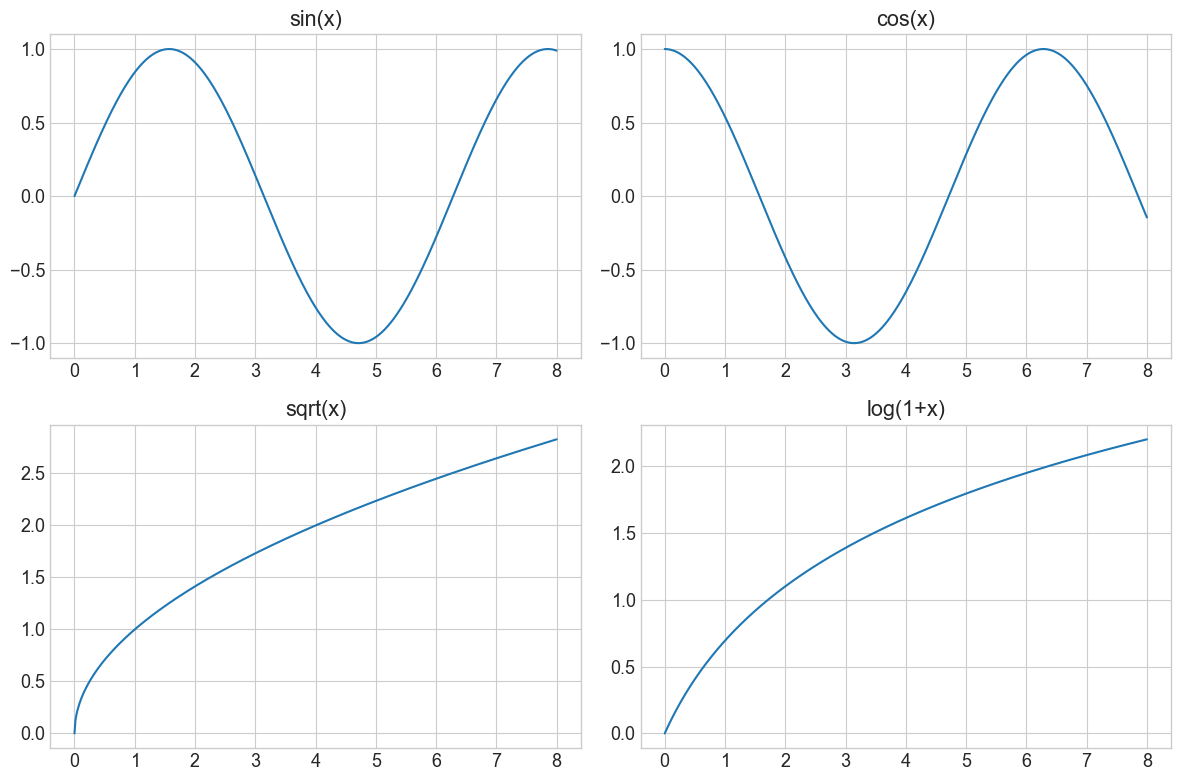

In [9]:
fig = plt.figure(figsize=(12, 8))

fonctions = [
    ("sin(x)", np.sin(x)),
    ("cos(x)", np.cos(x)),
    ("sqrt(x)", np.sqrt(x)),
    ("log(1+x)", np.log1p(x))
]

for i, (titre, valeurs) in enumerate(fonctions):
    ax = fig.add_subplot(2, 2, i + 1)
    ax.plot(x, valeurs)
    ax.set_title(titre)

plt.tight_layout()
plt.show()

<span style="color:blue">**QUESTION : À quoi sert ce code ? Que signifient les trois arguments de `add_subplot(2, 2, i+1)` ?**</span>

<span style="color:red">**CORRECTION :** Le code construit une figure contenant quatre sous-graphiques. Le premier `2` indique deux lignes, le second `2` deux colonnes et `i+1` la position du sous-graphe courant dans cette grille.</span>

<span style="color:blue">**QUESTION : Modifier le principe précédent pour créer une figure de 1 ligne et 3 colonnes contenant `sin(x)`, `cos(x)` et `sin(x)+cos(x)`.**</span>

<span style="color:red">**CORRECTION :** Il faut utiliser une grille `1 × 3` et placer successivement les trois graphiques aux positions 1, 2 et 3.</span>

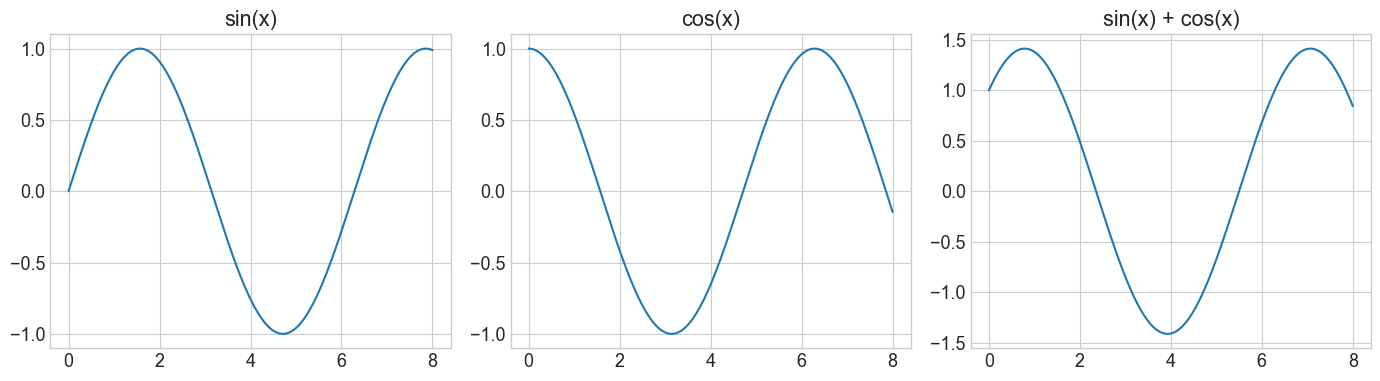

In [10]:
fig = plt.figure(figsize=(14, 4))

courbes = [
    ("sin(x)", np.sin(x)),
    ("cos(x)", np.cos(x)),
    ("sin(x) + cos(x)", np.sin(x) + np.cos(x))
]

for i, (titre, valeurs) in enumerate(courbes):
    ax = fig.add_subplot(1, 3, i + 1)
    ax.plot(x, valeurs)
    ax.set_title(titre)

plt.tight_layout()
plt.show()

## 4. Afficher un diagramme en barres

Un diagramme en barres est adapté pour comparer des valeurs associées à des catégories.

Nous allons comparer le nombre moyen de trajets quotidiens réalisés avec différents modes de transport
dans un petit échantillon.

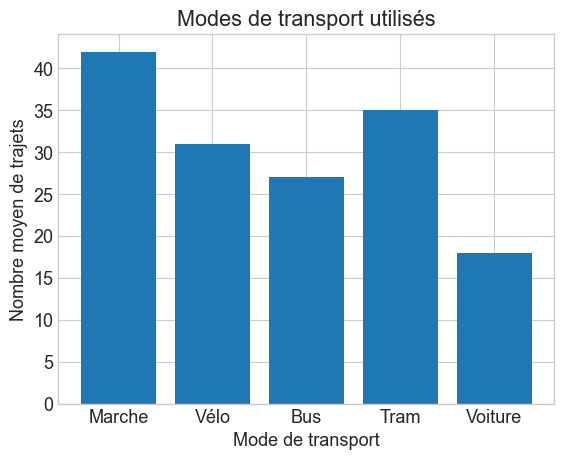

In [11]:
modes = ["Marche", "Vélo", "Bus", "Tram", "Voiture"]
trajets = [42, 31, 27, 35, 18]

positions = np.arange(len(modes))

plt.bar(positions, trajets)
plt.xticks(positions, modes)
plt.xlabel("Mode de transport")
plt.ylabel("Nombre moyen de trajets")
plt.title("Modes de transport utilisés")
plt.show()

<span style="color:blue">**QUESTION : Modifier le graphique pour afficher les barres horizontalement.**</span>

<span style="color:red">**CORRECTION :** La fonction `plt.barh` crée un diagramme en barres horizontales.</span>

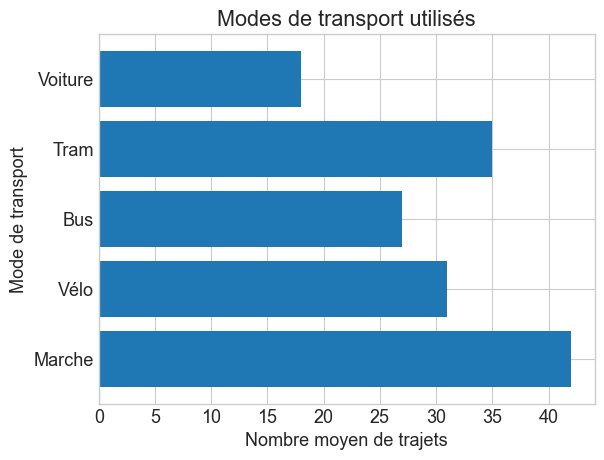

In [12]:
plt.barh(modes, trajets)
plt.xlabel("Nombre moyen de trajets")
plt.ylabel("Mode de transport")
plt.title("Modes de transport utilisés")
plt.show()

<span style="color:blue">**QUESTION : Quel mode de transport possède la valeur maximale ? Trouver la réponse avec NumPy.**</span>

<span style="color:red">**CORRECTION :** `np.argmax(trajets)` renvoie la position du maximum, qui peut ensuite servir à accéder au nom du mode.</span>

In [13]:
indice_max = np.argmax(trajets)
print(modes[indice_max], trajets[indice_max])

Marche 42


## 5. Afficher un diagramme circulaire

Un diagramme circulaire permet de représenter la répartition d'un total entre plusieurs catégories.

Exemple : composition des déchets collectés lors d'une opération de tri.

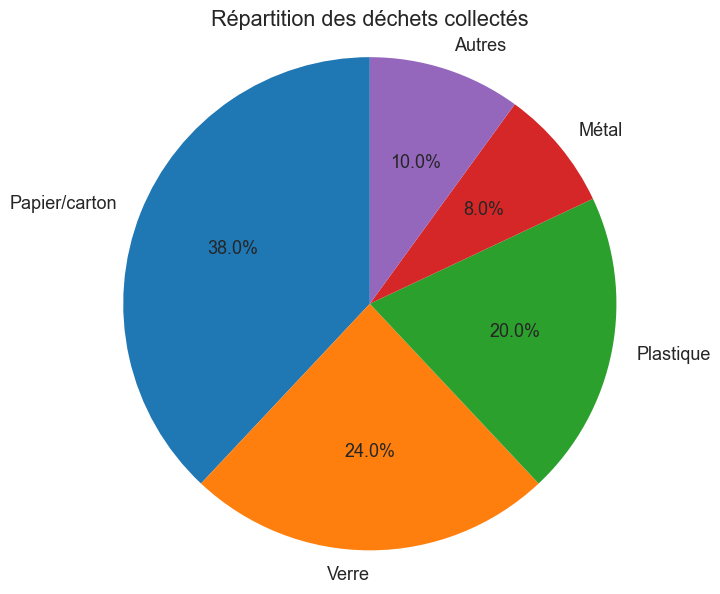

In [14]:
categories = ["Papier/carton", "Verre", "Plastique", "Métal", "Autres"]
quantites = [38, 24, 20, 8, 10]

plt.figure(figsize=(7, 7))
plt.pie(
    quantites,
    labels=categories,
    autopct="%1.1f%%",
    startangle=90
)
plt.title("Répartition des déchets collectés")
plt.axis("equal")
plt.show()

<span style="color:blue">**QUESTION : À quoi sert l'argument `autopct='%1.1f%%'` ?**</span>

<span style="color:red">**CORRECTION :** Il demande à Matplotlib d'afficher sur chaque secteur sa proportion en pourcentage, avec une décimale.</span>

<span style="color:blue">**QUESTION : Créer un diagramme circulaire pour les dépenses mensuelles suivantes : logement 650 €, alimentation 280 €, transport 120 €, loisirs 150 €.**</span>

<span style="color:red">**CORRECTION :** Il suffit de fournir les quatre catégories et leurs montants à `plt.pie`.</span>

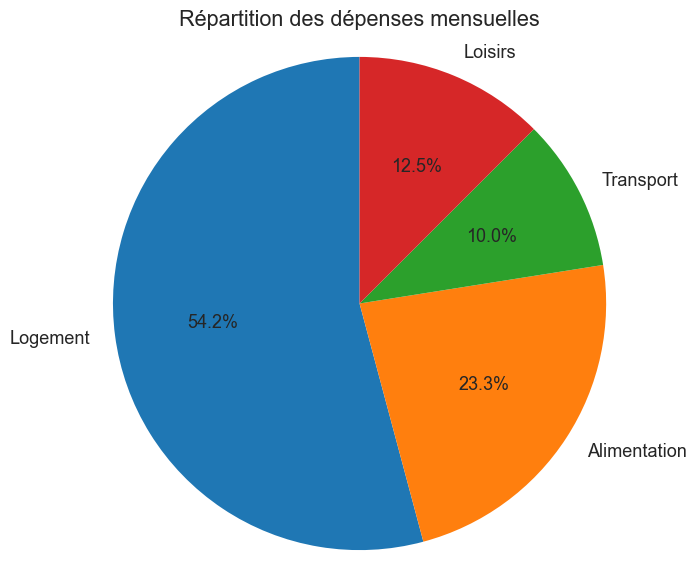

In [15]:
postes = ["Logement", "Alimentation", "Transport", "Loisirs"]
depenses = [650, 280, 120, 150]

plt.figure(figsize=(7, 7))
plt.pie(depenses, labels=postes, autopct="%1.1f%%", startangle=90)
plt.title("Répartition des dépenses mensuelles")
plt.axis("equal")
plt.show()

## 6. Afficher un diagramme à moustaches

Le **boxplot** permet de comparer rapidement la distribution de plusieurs groupes :
médiane, quartiles, dispersion et valeurs atypiques.

Nous allons comparer les temps de trajet domicile–travail de trois groupes.

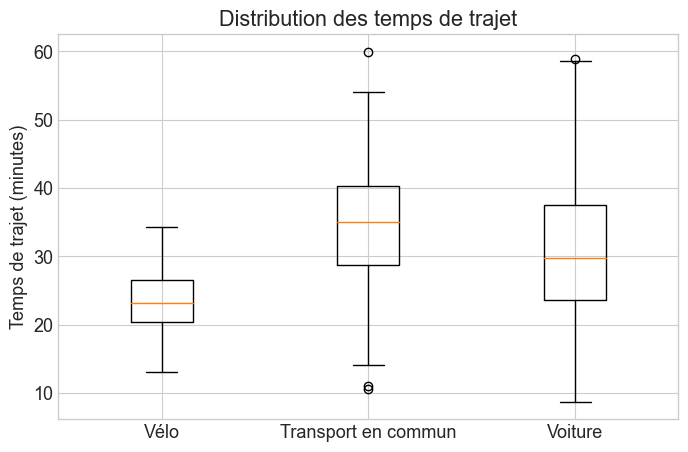

In [17]:
rng = np.random.default_rng(10)

velo = rng.normal(24, 5, 120)
transport_commun = rng.normal(37, 9, 120)
voiture = rng.normal(31, 11, 120)

donnees = [velo, transport_commun, voiture]

plt.figure(figsize=(8, 5))
plt.boxplot(
    donnees,
    labels=["Vélo", "Transport en commun", "Voiture"]
)
plt.ylabel("Temps de trajet (minutes)")
plt.title("Distribution des temps de trajet")
plt.show()

<span style="color:blue">**QUESTION : Quel groupe semble avoir la durée médiane la plus élevée ?**</span>

<span style="color:red">**CORRECTION :** Avec les données générées ici, le groupe `Transport en commun` présente généralement la médiane la plus élevée.</span>

<span style="color:blue">**QUESTION : Calculer les médianes numériques des trois groupes avec NumPy.**</span>

<span style="color:red">**CORRECTION :** `np.median` permet de vérifier numériquement ce que suggère le diagramme.</span>

In [18]:
print("Vélo :", np.median(velo))
print("Transport en commun :", np.median(transport_commun))
print("Voiture :", np.median(voiture))

Vélo : 23.13230015775135
Transport en commun : 35.046416767755105
Voiture : 29.734689595342534


## 7. Exercice de synthèse

On dispose des données suivantes concernant la fréquentation hebdomadaire d'une médiathèque.

In [19]:
jours = ["Lundi", "Mardi", "Mercredi", "Jeudi", "Vendredi", "Samedi"]
entrees = np.array([120, 135, 210, 150, 175, 260])
incertitudes = np.array([8, 10, 15, 9, 11, 18])

<span style="color:blue">**QUESTION : 1. Représenter le nombre d'entrées avec un diagramme en barres.**</span>

<span style="color:red">**CORRECTION :** Les jours constituent les catégories et `entrees` les hauteurs des barres.</span>

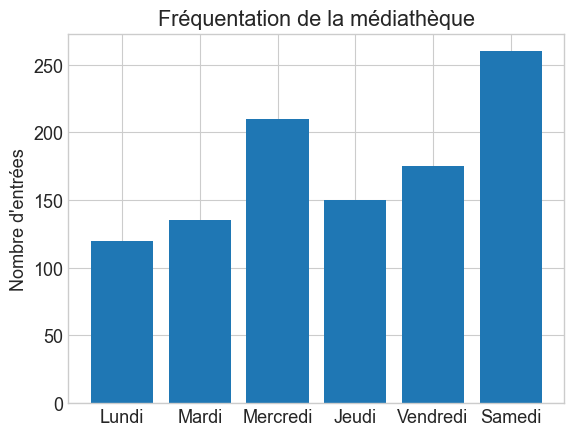

In [20]:
plt.bar(jours, entrees)
plt.ylabel("Nombre d'entrées")
plt.title("Fréquentation de la médiathèque")
plt.show()

<span style="color:blue">**QUESTION : 2. Représenter les mêmes données sous forme de points avec des barres d'erreur.**</span>

<span style="color:red">**CORRECTION :** `plt.errorbar` permet d'utiliser le tableau `incertitudes` comme valeurs de `yerr`.</span>

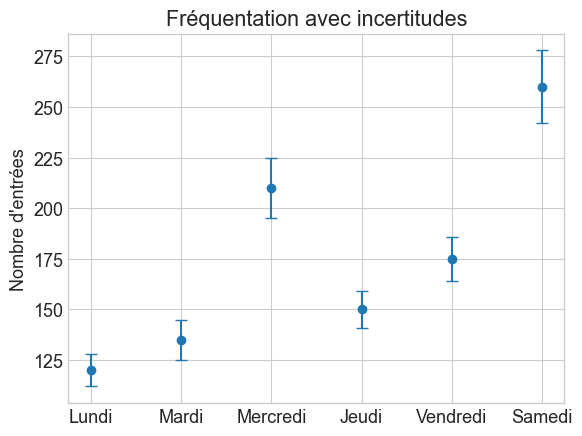

In [21]:
positions = np.arange(len(jours))

plt.errorbar(
    positions,
    entrees,
    yerr=incertitudes,
    fmt="o",
    capsize=4
)
plt.xticks(positions, jours)
plt.ylabel("Nombre d'entrées")
plt.title("Fréquentation avec incertitudes")
plt.show()

<span style="color:blue">**QUESTION : 3. Calculer le jour le plus fréquenté et l'afficher.**</span>

<span style="color:red">**CORRECTION :** `np.argmax(entrees)` renvoie l'indice de la fréquentation maximale.</span>

In [22]:
indice = np.argmax(entrees)
print(jours[indice], entrees[indice])

Samedi 260


<span style="color:blue">**QUESTION : 4. Créer une figure composée de deux sous-graphiques : à gauche le diagramme en barres, à droite un diagramme circulaire de la répartition des entrées.**</span>

<span style="color:red">**CORRECTION :** Une grille 1 × 2 permet de juxtaposer les deux représentations dans une même figure.</span>

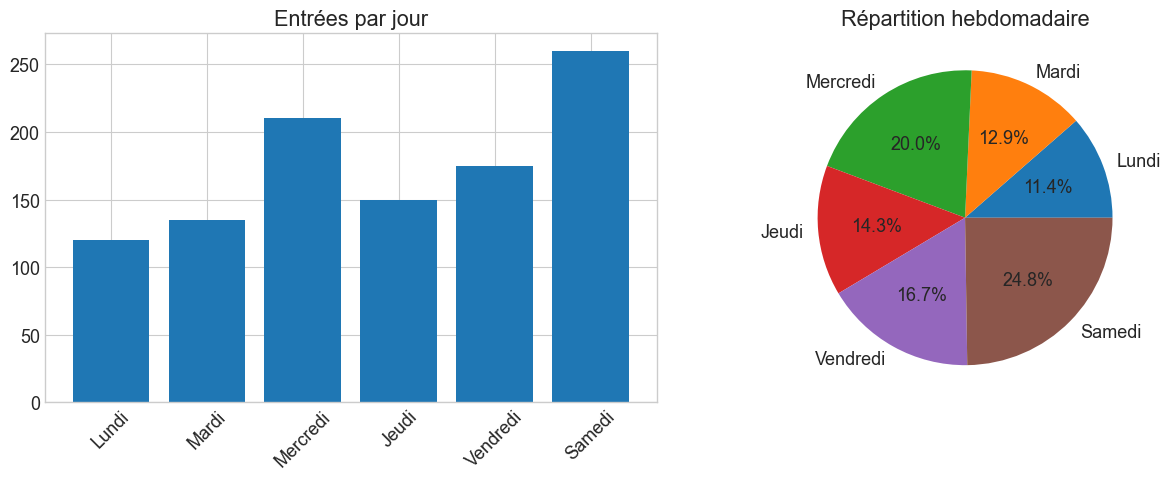

In [23]:
fig = plt.figure(figsize=(13, 5))

ax1 = fig.add_subplot(1, 2, 1)
ax1.bar(jours, entrees)
ax1.set_title("Entrées par jour")
ax1.tick_params(axis="x", rotation=45)

ax2 = fig.add_subplot(1, 2, 2)
ax2.pie(entrees, labels=jours, autopct="%1.1f%%")
ax2.set_title("Répartition hebdomadaire")

plt.tight_layout()
plt.show()

## À retenir

Matplotlib permet de choisir une représentation adaptée au type de données :

- `plot` pour des courbes ;
- `errorbar` pour des mesures avec incertitudes ;
- `fill_between` pour représenter une zone autour d'une courbe ;
- `bar` / `barh` pour comparer des catégories ;
- `pie` pour représenter une répartition ;
- `boxplot` pour comparer des distributions ;
- `add_subplot` pour organiser plusieurs graphiques dans une même figure.

Au-delà du choix du graphique, pensez toujours à ajouter des **titres, labels et légendes** afin que la visualisation puisse être comprise sans avoir à lire le code.